In [199]:
#regular stuff

import lightkurve as lk
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pandas as pd
from astropy.timeseries import LombScargle

%matplotlib inline

In [200]:
def getOOE(dataframe, jump_threshold):
    ''' identifies the out-of-eclipse (OOE) data points in a light curve'''
    
    Npts = len(dataframe)
    # Compute the median of the entire light curve (including eclipses/flares).
    median_raw = np.nanmedian(dataframe["flux"])
    
    # Compute a running median every 3 points.
    medians = np.zeros(Npts)
    for i in range(Npts):
        if i < Npts-2:
            medians[i] = np.nanmedian(dataframe["flux"].iloc[[i,i+1,i+2]])
        elif i == Npts-2:
            medians[i] = np.nanmedian(dataframe["flux"].iloc[[i,i+1]])
        else:
            medians[i] = dataframe["flux"].iloc[i]
    
    # Check for points where the median changes by too much.
    bool_keep = np.zeros(Npts) + 1  # setting them all to True to start
    for i in range(Npts-1):
        if abs(medians[i]-medians[i+1]) > jump_threshold or abs(medians[i]-median_raw) > 100:
            bool_keep[i:i+3] = 0
            bool_keep[i-3:i] = 0
    indx_OOE = np.where(bool_keep)[0]
    
    return(indx_OOE)

In [201]:
#getting light curve data for Freya
search_result = lk.search_lightcurve("TIC 0148611095") #Tyr
print(search_result)
indx_lc = np.where(search_result.table["author"] == "TESS-SPOC")[0] 
lc_many = search_result[indx_lc].download_all()
data0_raw = lc_many[0].to_pandas()
#   Sector 21
indx_ok = np.where(np.isfinite(data0_raw["flux"]))[0]
data0 = data0_raw.filter(items=data0_raw.index[indx_ok], axis=0)
data0.index = (((data0.index + 2457000) -2451545.25) /356.25) + 2000 #in years

#   Some points...
Npts0 = len(data0)

SearchResult containing 15 data products.

 #      mission     year       author      exptime target_name distance
                                              s                 arcsec 
--- --------------- ---- ----------------- ------- ----------- --------
  0  TESS Sector 09 2019              SPOC     120   148611095      0.0
  1  TESS Sector 62 2023              SPOC     120   148611095      0.0
  2  TESS Sector 72 2023              SPOC     120   148611095      0.0
  3 TESS Sector 100 2026              SPOC     120   148611095      0.0
  4  TESS Sector 09 2019         TESS-SPOC    1800   148611095      0.0
  5  TESS Sector 36 2021         TESS-SPOC     600   148611095      0.0
  6  TESS Sector 62 2023         TESS-SPOC     200   148611095      0.0
  7  TESS Sector 72 2023         TESS-SPOC     200   148611095      0.0
  8  TESS Sector 09 2019               QLP    1800   148611095      0.0
  9  TESS Sector 36 2021               QLP     600   148611095      0.0
 10  TESS Sector 62 2

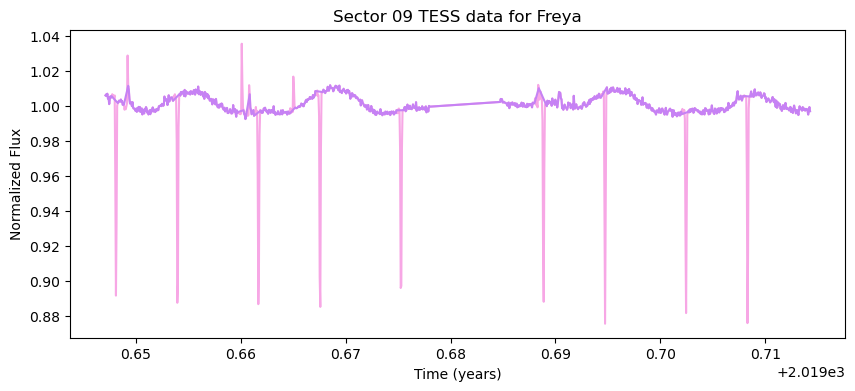

In [202]:
#first section 
indx_outofeclipse0 = getOOE(data0, 20)
    #Median flux but only for the OOE points
median0 =  np.median(data0['flux'].iloc[indx_outofeclipse0])  
median0_err = np.median(data0['flux_err'].iloc[indx_outofeclipse0])
    #Making the df 
data0_normed = data0[["flux", "flux_err"]].copy() 
    #Normalising flux and error propagation  
data0_normed["flux"] = data0['flux']/median0
data0_normed["flux_err"] = data0['flux_err']/median0_err
    #plotting
fig, ax = plt.subplots(1,1, figsize=(10,4)) 
ax.plot(data0_normed.index, data0_normed["flux"], c="#f7a7e5")
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#c682f4")
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
plt.title("Sector 09 TESS data for Freya")
plt.show()

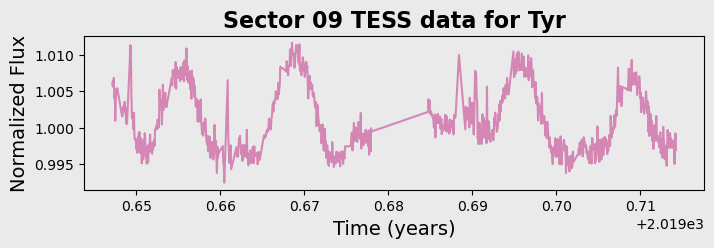

In [203]:
fig, ax = plt.subplots(1,1, figsize=(8,2)) 
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#D487B4")
plt.ylabel("Normalized Flux", fontsize='14')
plt.xlabel("Time (years)", fontsize='14')
plt.title("Sector 09 TESS data for Tyr", fontsize='16', fontweight='bold')
fig.set_facecolor('#EAEAEA')
ax.set_facecolor('#EAEAEA')
plt.show()

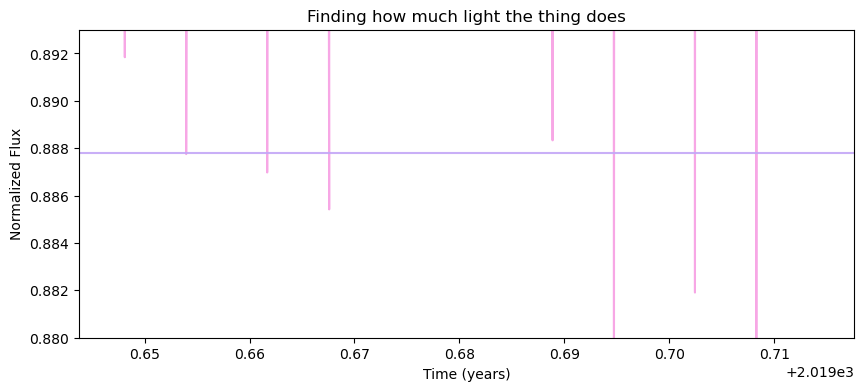

In [204]:
depth = 0.8878

fig, ax = plt.subplots(1,1, figsize=(10,4)) 
ax.plot(data0_normed.index, data0_normed["flux"], c="#f7a7e5")
ax.axhline(y=depth, color="#c3a7f7", linestyle='-', label=f'secondary', alpha=0.9)
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
plt.title("Finding how much light the thing does")
ax.set_ylim(0.88, 0.893)
#ax.set_xlim(2019.645, 2019.66)
plt.show()

In [205]:
primary = depth
print(primary)
secondary = (1-depth)
print(f"we lose {(1-depth)*100:.3}% of the light when secondary star is blocked")
print(f"The primary start contributes {primary*100:.3}% of the light")
print(f"The secondary star contributes {secondary*100:.3}% of the light")

0.8878
we lose 11.2% of the light when secondary star is blocked
The primary start contributes 88.8% of the light
The secondary star contributes 11.2% of the light


In [206]:
data_all = data0_normed.iloc[indx_outofeclipse0]
print(f"length: {len(data_all)}")

length: 904


[4.87001666 4.86532511 4.87471726]
  Top 3 periods (in days)? =  4.870016655790078 4.865325107525836 4.874717260744092
  (their powers were:  [0.56212409 0.56209808 0.56205627]


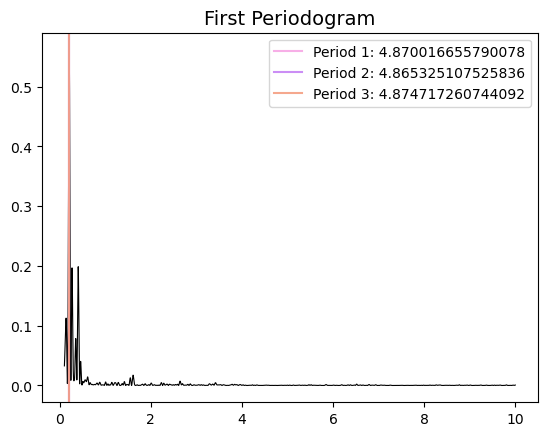

In [207]:
possiblef = np.linspace(0.1, 10, 50000)
power = LombScargle(data_all.index.values*365.25,data_all['flux'].values).power(possiblef)
frequency = possiblef
period = 1 / frequency


indx_sorted = (-power).argsort()
print(period[indx_sorted[0:3]])
p1, p2, p3 = period[indx_sorted[0:3]] #period but in days??
print("  Top 3 periods (in days)? = ",p1, p2, p3) 
print("  (their powers were: ",power[indx_sorted[0:3]])

fig, ax = plt.subplots()
ax.plot(frequency, power, c='black', linewidth = '0.8')
ax.axvline(x=1/p1, color='#f7a7e5', linestyle='-', label=f'Period 1: {p1}', alpha=0.9)
ax.axvline(x=1/p2, color='#c682f4', linestyle='-', label=f'Period 2: {p2}', alpha=0.9)
ax.axvline(x=1/p3, color="#f49f82", linestyle='-', label=f'Period 3: {p3}', alpha=0.9)
ax.set_title('First Periodogram', fontsize=14)
#ax.set_xlim(0.5,8) #goes to 25, but it's a flat line so I'm zooming in!
ax.legend()
plt.show()


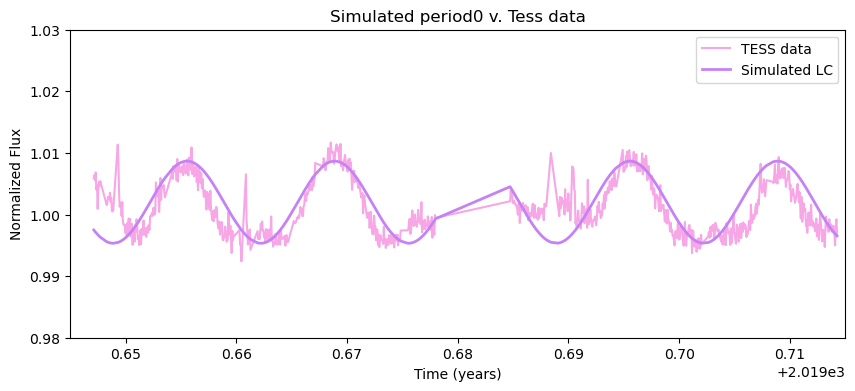

In [208]:

#Plotting a simulated LC
    #range of x-values 
x_vals = data_all.index
    #choosing the best period 
period0 = p1 / 365.25

#creating a sin function for the simulated LC
    #amplitude...
amp0 = 1 / 150 #to get the sin function between 1.02 and 0.98?
    #omega
omega0 = (2 * np.pi) / period0 
    #vertical shift
vShift0 = 1.002
    #horiziontal shift???
hShift0 = -2.5
#actual function!
sim0 = amp0 * np.sin(omega0 * x_vals +hShift0) + vShift0 

#plotting 
fig, ax = plt.subplots(1,1, figsize=(10,4)) 
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(x_vals, sim0, c="#c682f4", label='Simulated LC', linewidth='2')
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Simulated period0 v. Tess data")
ax.set_ylim(0.98, 1.03)
ax.set_xlim(2019.645, 2019.715)
plt.legend(loc='best')

plt.show()

In [209]:
print(f"The total flux has an amplitude of {amp0:.3}")
print(primary)
print(amp0*primary)
print(f"the primary flux must have an amplitude of {amp0*primary:.3}")
print(f"the primary flux must have an amplitude of {amp0*secondary:.3}")

The total flux has an amplitude of 0.00667
0.8878
0.0059186666666666676
the primary flux must have an amplitude of 0.00592
the primary flux must have an amplitude of 0.000748


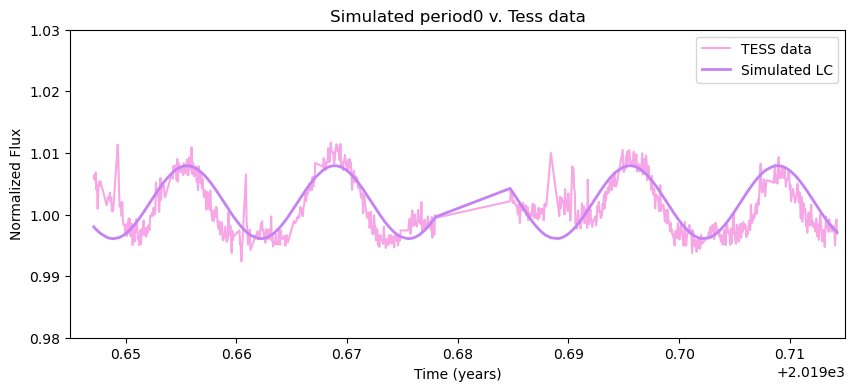

In [210]:

#Plotting a simulated LC
    #range of x-values 
x_vals = data_all.index
    #choosing the best period 
period0 = p1 / 365.25

#creating a sin function for the simulated LC
    #amplitude...
amp0 = 1 / 150 * primary#to get the sin function between 1.02 and 0.98?
    #omega
omega0 = (2 * np.pi) / period0 
    #vertical shift
vShift0 = 1.002
    #horiziontal shift???
hShift0 = -2.5
#actual function!
sim0 = amp0 * np.sin(omega0 * x_vals +hShift0) + vShift0 

#plotting 
fig, ax = plt.subplots(1,1, figsize=(10,4)) 
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(x_vals, sim0, c="#c682f4", label='Simulated LC', linewidth='2')
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Simulated period0 v. Tess data")
ax.set_ylim(0.98, 1.03)
ax.set_xlim(2019.645, 2019.715)
plt.legend(loc='best')

plt.show()

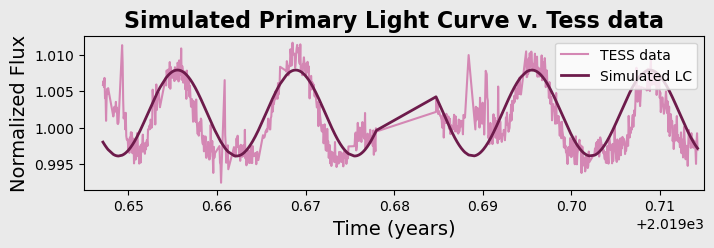

In [223]:
fig, ax = plt.subplots(1,1, figsize=(8,2)) 
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#D487B4", label='TESS data')
ax.plot(x_vals, sim0, c="#6d1b4b", label='Simulated LC', linewidth='2')
plt.ylabel("Normalized Flux", fontsize='14')
plt.xlabel("Time (years)", fontsize='14')
ax.set_title("Simulated Primary Light Curve v. Tess data", fontsize='16', fontweight='bold')
ax.set_xlim(2019.645, 2019.715)
fig.set_facecolor('#EAEAEA')
ax.set_facecolor('#EAEAEA')
plt.legend(loc='upper right')
plt.show()

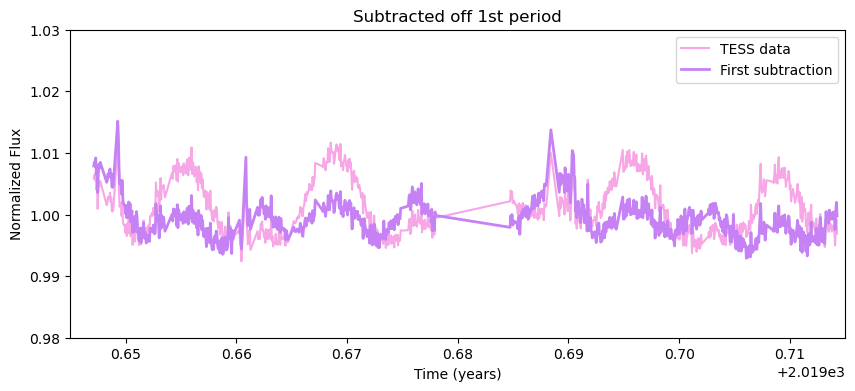

In [212]:
#subtracting off the simulated LC
    #subtracted flux
subtracted0 = data_all['flux'] - sim0
    #subtracting off from error??
error0 = data_all['flux_err'] - sim0

#putting into a new df 
sub0_stuff = {
    'flux' : subtracted0, 
    'flux_err' : error0, 
    'time' : x_vals
}
sub0 = pd.DataFrame(sub0_stuff)

#plotting??
fig, ax = plt.subplots(1,1, figsize=(10,4))
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(sub0['time'], sub0['flux'] + 1.00, c="#c682f4", label='First subtraction', linewidth='2')
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Subtracted off 1st period")
ax.set_ylim(0.98, 1.03)
ax.set_xlim(2019.645, 2019.715)
plt.legend(loc='best')
plt.show()

[2.02742759 2.0282418  2.02661403]
  Top 3 periods (in days)? =  2.0274275889754394 2.0282418037109453 2.0266140276922076
  (their powers were:  [0.3573607  0.35735557 0.35729738]


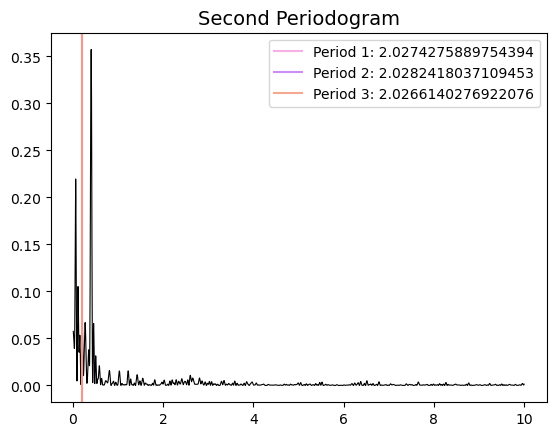

In [213]:
possiblef = np.linspace(0.01, 10, 50000)
power = LombScargle(sub0.index.values*365.25,sub0['flux'].values).power(possiblef)
frequency = possiblef


indx_sorted = (-power).argsort()
print(period[indx_sorted[0:3]])
p11, p22, p33 = period[indx_sorted[0:3]] #period but in days??
print("  Top 3 periods (in days)? = ",p11, p22, p33) 
print("  (their powers were: ",power[indx_sorted[0:3]])

fig, ax = plt.subplots()
ax.plot(frequency, power, c='black', linewidth = '0.8')
ax.axvline(x=1/p1, color='#f7a7e5', linestyle='-', label=f'Period 1: {p11}', alpha=0.9)
ax.axvline(x=1/p2, color='#c682f4', linestyle='-', label=f'Period 2: {p22}', alpha=0.9)
ax.axvline(x=1/p3, color="#f49f82", linestyle='-', label=f'Period 3: {p33}', alpha=0.9)
ax.set_title('Second Periodogram', fontsize=14)
#ax.set_xlim(0.5,8) #goes to 25, but it's a flat line so I'm zooming in!
ax.legend()
plt.show()

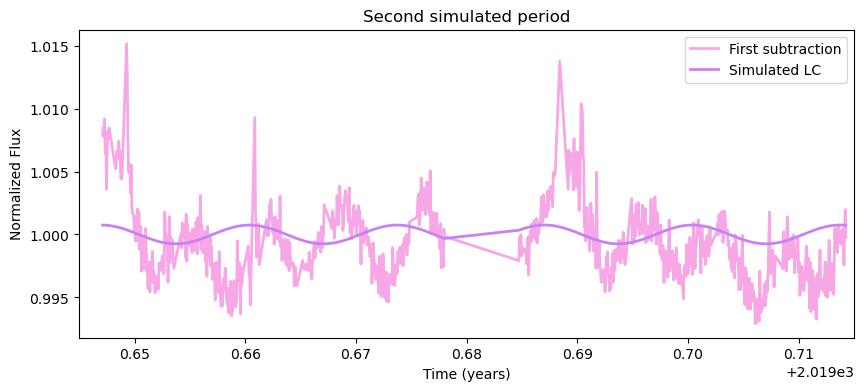

In [214]:
#Plotting a simulated LC
    #choosing the best period 
period1 = p11 / 365.25

#creating a sin function for the simulated LC
    #amplitude...
amp1 = 1 / 150 * secondary #to get the sin function between 1.02 and 0.98?
    #omega
omega1 = (2 * np.pi) / period0 
    #vertical shift
vShift1 = 1
    #horiziontal shift???
hShift1 = 1.5
#actual function!
sim1 = amp1 * np.sin(omega1 * x_vals +hShift1) + vShift1 

#plotting 
fig, ax = plt.subplots(1,1, figsize=(10,4)) 
#ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(sub0['time'], sub0['flux'] + 1.00, c="#f7a7e5", label='First subtraction', linewidth='2')
ax.plot(x_vals, sim1, c="#c682f4", label='Simulated LC', linewidth='2')
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Second simulated period")
#ax.set_ylim(0.98, 1.03)
ax.set_xlim(2019.645, 2019.715)
plt.legend(loc='best')
plt.show()

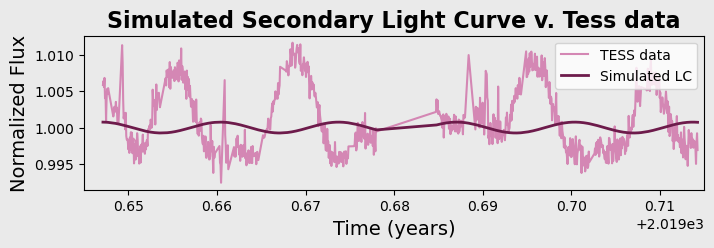

In [225]:
fig, ax = plt.subplots(1,1, figsize=(8,2)) 
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#D487B4", label='TESS data')
ax.plot(x_vals, sim1, c="#6d1b4b", label='Simulated LC', linewidth='2')
plt.ylabel("Normalized Flux", fontsize='14')
plt.xlabel("Time (years)", fontsize='14')
ax.set_title("Simulated Secondary Light Curve v. Tess data", fontsize='16', fontweight='bold')
ax.set_xlim(2019.645, 2019.715)
fig.set_facecolor('#EAEAEA')
ax.set_facecolor('#EAEAEA')
plt.legend(loc='upper right')
plt.show()

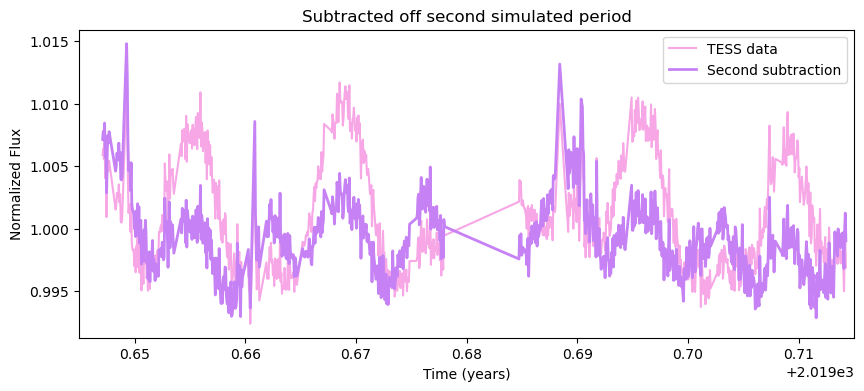

In [215]:
#subtracting off the simulated LC
    #subtracted flux
subtracted1 = sub0['flux'] - sim1
    #subtracting off from error??
error1 = sub0['flux_err'] - sim1

#putting into a new df 
sub1_stuff = {
    'flux' : subtracted1, 
    'flux_err' : error1, 
    'time' : x_vals
}
sub1 = pd.DataFrame(sub1_stuff)

#plotting??
fig, ax = plt.subplots(1,1, figsize=(10,4))
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(sub1['time'], sub1['flux']+2, c="#c682f4", label='Second subtraction', linewidth='2')
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Subtracted off second simulated period")
#ax.set_ylim(0.98, 1.03)
ax.set_xlim(2019.645, 2019.715)
plt.legend(loc='best')
plt.show()

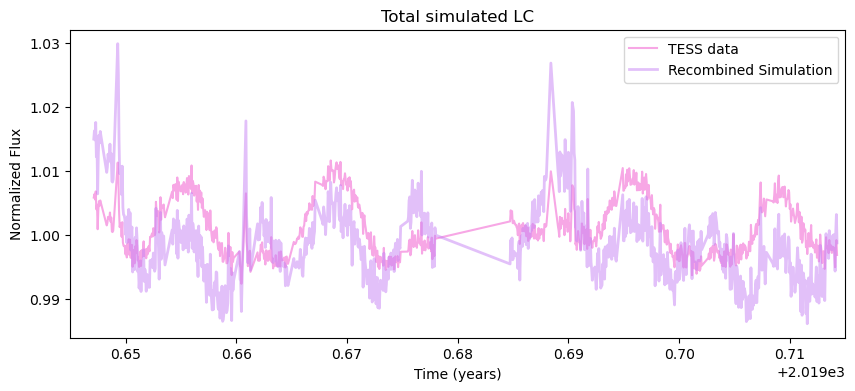

In [216]:
simTotal = sub1['flux'] + sub0['flux']

fig, ax = plt.subplots(1,1, figsize=(10,4))
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(sub1['time'], simTotal+2, c="#c682f4", label='Recombined Simulation', linewidth='2',alpha=0.5)
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Total simulated LC")
#ax.set_ylim(0.98, 1.03)
ax.set_xlim(2019.645, 2019.715)
plt.legend(loc='best')
plt.show()

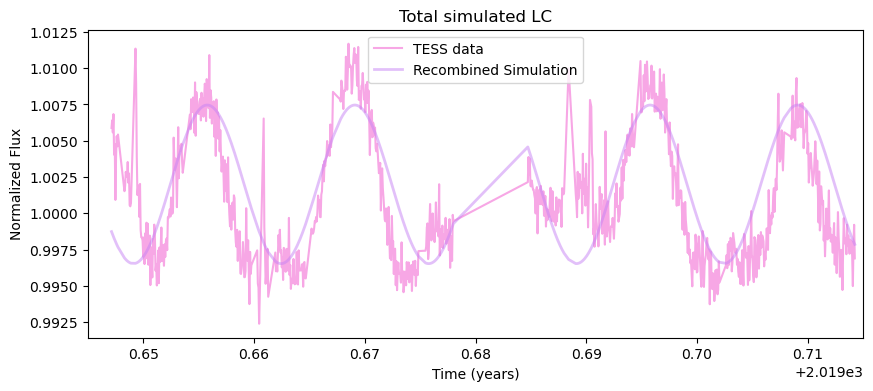

In [217]:
simTotal = sim1 + sim0 -1

fig, ax = plt.subplots(1,1, figsize=(10,4))
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(sub1['time'], simTotal, c="#c682f4", label='Recombined Simulation', linewidth='2',alpha=0.5)
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Total simulated LC")
#ax.set_ylim(0.98, 1.03)
ax.set_xlim(2019.645, 2019.715)
plt.legend(loc='best')
plt.show()

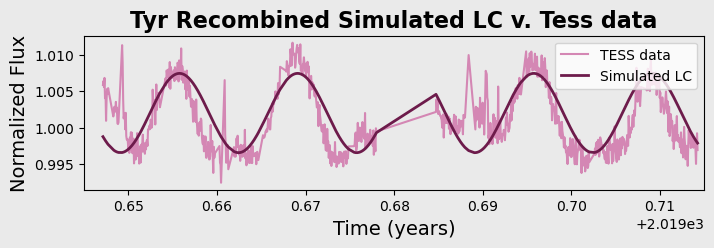

In [227]:
fig, ax = plt.subplots(1,1, figsize=(8,2)) 
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#D487B4", label='TESS data')
ax.plot(x_vals, simTotal, c="#6d1b4b", label='Simulated LC', linewidth='2')
plt.ylabel("Normalized Flux", fontsize='14')
plt.xlabel("Time (years)", fontsize='14')
ax.set_title("Tyr Recombined Simulated LC v. Tess data", fontsize='16', fontweight='bold')
ax.set_xlim(2019.645, 2019.715)
fig.set_facecolor('#EAEAEA')
ax.set_facecolor('#EAEAEA')
plt.legend(loc='upper right')
plt.show()

In [ ]:
print(f"Rotation Period of Star 1 {p1}.")
print(f"Rotation Period of Star 2 {p11}.")

4.870016655790078
2.0274275889754394
